<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab4SOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №4: Self-supervised learning визуальных представлений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Извлечь frozen DINO embeddings.
- Сравнить k-NN и linear probe при 1/10/100% меток.
- Исследовать ближайших соседей и shortcut features.


## Теоретическая часть

Self-supervised encoder обучается без классов: contrastive objective сближает представления двух views одного изображения, masked modeling восстанавливает скрытые токены. Качество representation проверяют frozen k-NN и linear probe.

![DINO](https://raw.githubusercontent.com/facebookresearch/dino/main/.github/dino.gif)


### Математическая постановка

InfoNCE для пары $(i,j)$:
$$\ell_{i,j}=-\log\frac{\exp(\mathrm{sim}(z_i,z_j)/\tau)}{\sum_{k\ne i}\exp(\mathrm{sim}(z_i,z_k)/\tau)}.$$
Linear probe обучает только $W$ в $\hat y=\arg\max Wz$.


### Материалы

- [DINOv2](https://github.com/facebookresearch/dinov2)
- [SimCLR](https://arxiv.org/abs/2002.05709)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Извлечь frozen DINO embeddings.
2. Сравнить k-NN и linear probe при 1/10/100% меток.
3. Исследовать ближайших соседей и shortcut features.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** DINOv2 ViT-S/14 frozen, FP16.
- **Ограничение данных:** до 5 000 изображений.
- **Fallback:** ResNet18 frozen embeddings.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [ ]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
# сохраняем артефакты на Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ARTIFACTS = Path("/content/drive/MyDrive/cv_lab4_artifacts")
    ARTIFACTS.mkdir(parents=True, exist_ok=True)
except ImportError:
    pass
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


Mounted at /content/drive
{'device': 'cpu', 'fast_dev_run': False, 'data_root': '/data'}


In [ ]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Стратифицированные разбиения CIFAR-10

*Вес: 1 балл.*

**Постановка.** Train, validation и test изолируют подбор параметров линейного probe.

Выполните следующие действия:
1. Загрузите CIFAR-10 и стратифицируйте train.
2. Подготовьте неизменяемые индексы test.

**Результат.** Датасет ds, загрузчик loader и длины трёх выборок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Subset
from collections import defaultdict

#загрузка CIFAR-10 (без transform)
train_full = torchvision.datasets.CIFAR10(
    root=str(DATA_ROOT), train=True, download=True, transform=None
)
test_ds = torchvision.datasets.CIFAR10(
    root=str(DATA_ROOT), train=False, download=True, transform=None
)

# стратифицированное разбиение train на train/val (80/20)
targets = np.array(train_full.targets)
indices_by_class = defaultdict(list)
for idx, label in enumerate(targets):
    indices_by_class[label].append(idx)

train_indices, val_indices = [], []
for label, idxs in indices_by_class.items():
    np.random.seed(SEED + label)
    np.random.shuffle(idxs)
    split = int(0.8 * len(idxs))
    train_indices.extend(idxs[:split])
    val_indices.extend(idxs[split:])

# ограничение до 5000 изображений
MAX_TOTAL = 5000 if not FAST_DEV_RUN else 500
rng = np.random.RandomState(SEED)

if len(train_indices) > MAX_TOTAL * 0.8:
    train_indices = rng.choice(train_indices, size=int(MAX_TOTAL*0.8), replace=False)
if len(val_indices) > MAX_TOTAL * 0.2:
    val_indices = rng.choice(val_indices, size=int(MAX_TOTAL*0.2), replace=False)
# test ограничиваем до 2000
n_test = 2000 if not FAST_DEV_RUN else 200
test_indices = np.arange(n_test)
print(f"Train: {len(train_indices)} | Val: {len(val_indices)} | Test: {len(test_indices)}")

# трансформации для DINOv2 (224x224, ImageNet нормализация)
transform_dino = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, base_ds, indices, transform):
        self.base = base_ds
        self.indices = list(indices)
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, label = self.base[self.indices[i]]
        if self.transform:
            img = self.transform(img)
        return img, label

train_ds = TransformSubset(train_full, train_indices, transform_dino)
val_ds = TransformSubset(train_full, val_indices, transform_dino)
test_ds_t = TransformSubset(test_ds, test_indices, transform_dino)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=False, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds_t, batch_size=64, shuffle=False, num_workers=2)


Train: 4000 | Val: 1000 | Test: 2000


### Предобученный DINOv2 и признаки

*Вес: 1 балл.*

**Постановка.** Frozen encoder предоставляет представления без доступа к меткам при извлечении.

Выполните следующие действия:
1. Загрузите DINOv2 ViT-S/14.
2. Сохраните нормированные признаки и явные train/validation/test индексы.

**Результат.** embeddings.npz с фактическими DINO-признаками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
from tqdm.auto import tqdm

# загрузка DINOv2 ViT-S/14
dinov2 = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', pretrained=True)
dinov2 = dinov2.to(DEVICE)
dinov2.eval()

# извлечение признаков
@torch.no_grad()
def extract_embeddings(model, loader, device, desc="Extract"):
    all_feats, all_labels = [], []
    for imgs, labels in tqdm(loader, desc=desc):
        imgs = imgs.to(device)
        feats = model(imgs) #(B, 384) CLS token
        all_feats.append(feats.cpu().numpy())
        all_labels.append(labels.numpy())
    return np.concatenate(all_feats), np.concatenate(all_labels)

# извлечение для train/val/test
X_train, y_train = extract_embeddings(dinov2, train_loader, DEVICE, "Train")
X_val, y_val = extract_embeddings(dinov2, val_loader,   DEVICE, "Val")
X_test, y_test = extract_embeddings(dinov2, test_loader,  DEVICE, "Test")

# L2-нормализация (для kNN и linear probe)
def l2_norm(X):
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)
X_train_n = l2_norm(X_train)
X_val_n   = l2_norm(X_val)
X_test_n  = l2_norm(X_test)

np.savez(ARTIFACTS / "embeddings.npz",
         X_train=X_train_n, y_train=y_train,
         X_val=X_val_n,     y_val=y_val,
         X_test=X_test_n,   y_test=y_test,
         train_indices=train_indices, val_indices=val_indices, test_indices=test_indices)

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")


Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Train:   0%|          | 0/63 [00:00<?, ?it/s]

Val:   0%|          | 0/16 [00:00<?, ?it/s]

Test:   0%|          | 0/32 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e185c1a2de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e185c1a2de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e185c1a2de0>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/da

Train: (4000, 384) | Val: (1000, 384) | Test: (2000, 384)


Загрузил предобученную модель DINOv2, заморозил ее(то есть не меняем веса) и прогнал через через все картинки, получил для каждой картинки эмбединг длиной 384

### Подбор k-NN на validation

*Вес: 1 балл.*

**Постановка.** Число соседей следует выбирать без обращения к test.

Выполните следующие действия:
1. Обучите k-NN для предложенной сетки k.
2. Выберите k по validation accuracy.

**Результат.** Словарь knn_val и выбранный best_k.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# загрузка признаков
data = np.load(ARTIFACTS / "embeddings.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]

# сетка k
k_grid = [1, 3, 5, 10, 20, 50] if not FAST_DEV_RUN else [1, 3, 5]

knn_val = {}
for k in k_grid:
    knn = KNeighborsClassifier(n_neighbors=k, metric='cosine', n_jobs=-1)
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_val, knn.predict(X_val))
    knn_val[k] = acc
    print(f"k={k:2d}: val_acc = {acc:.4f}")

best_k = max(knn_val, key=knn_val.get)
print(f"\nBest k = {best_k}, val_acc = {knn_val[best_k]:.4f}")


k= 1: val_acc = 0.9440
k= 3: val_acc = 0.9510
k= 5: val_acc = 0.9500
k=10: val_acc = 0.9550
k=20: val_acc = 0.9500
k=50: val_acc = 0.9430

Best k = 10, val_acc = 0.9550


Обучил метод ближайших соседей с разными значениями k на train и проверил точность на val. То есть берем новую картинку (из val), смотрим на ее вектор-признак и ищем в train-выборке k картинок, чьи векторы самые близкие (по косинусному сходству). Потом смотрим, какого класса эти k соседей, и по большинству голосов определяем класс исходной.

### Линейная проверка и test

*Вес: 1 балл.*

**Постановка.** Frozen-признаки оценивают независимыми простыми классификаторами.

Выполните следующие действия:
1. Обучите k-NN и logistic regression только на train.
2. Вычислите test accuracy и macro-F1 после выбора k.

**Результат.** probes.json с измеренными test-метриками.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

data = np.load(ARTIFACTS / "embeddings.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test   = data["X_test"],  data["y_test"]

# k-NN с лучшим k на test
knn = KNeighborsClassifier(n_neighbors=best_k, metric='cosine', n_jobs=-1)
knn.fit(X_train, y_train)
knn_test_acc = accuracy_score(y_test, knn.predict(X_test))
knn_test_f1  = f1_score(y_test, knn.predict(X_test), average='macro')

# Logistic Regression (linear probe)
lr = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs', n_jobs=-1)
lr.fit(X_train, y_train)
lr_test_acc = accuracy_score(y_test, lr.predict(X_test))
lr_test_f1  = f1_score(y_test, lr.predict(X_test), average='macro')

probes = {
    "best_k": int(best_k),
    "knn_val_acc": float(knn_val[best_k]),
    "knn_test_acc": float(knn_test_acc),
    "knn_test_f1": float(knn_test_f1),
    "linear_test_acc": float(lr_test_acc),
    "linear_test_f1": float(lr_test_f1),
}
with open(ARTIFACTS / "probes.json", "w") as f:
    json.dump(probes, f, indent=2)

print(f"k-NN (k={best_k}): test_acc={knn_test_acc:.4f}, macro-F1={knn_test_f1:.4f}")
print(f"Linear probe: test_acc={lr_test_acc:.4f}, macro-F1={lr_test_f1:.4f}")


k-NN (k=10): test_acc=0.9595, macro-F1=0.9588
Linear probe: test_acc=0.9725, macro-F1=0.9722


Тут мы сравниваем два простых классификатора на замороженных фичах DINOv2, чтобы понять, насколько эти фичи хороши. k-NN (ищет 10 похожих соседей в train и голосует) дал 95.95%, а linear probe (обучаемая линейная модель, подбирает веса) дала 97.25%

### Кривая объёма разметки

*Вес: 1 балл.*

**Постановка.** Малые размеченные подмножества выявляют sample efficiency представления.

Выполните следующие действия:
1. Создайте сбалансированные подмножества train по фиксированному seed.
2. Обучите отдельный linear probe для каждой доли и сохраните результаты.

**Результат.** label_curve.json с числом объектов и измеренной точностью.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
data = np.load(ARTIFACTS / "embeddings.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test   = data["X_test"],  data["y_test"]

fractions = [0.01, 0.1, 1.0] if not FAST_DEV_RUN else [0.01, 0.1]
label_curve = []

for frac in fractions:
    if frac >= 1.0:
        X_sub, y_sub = X_train, y_train
    else:
        # сбалансированное подмножество
        sub_indices = []
        for c in range(10):
            idxs = np.where(y_train == c)[0]
            np.random.seed(SEED)
            n = max(1, int(len(idxs) * frac))
            sub_indices.extend(np.random.choice(idxs, n, replace=False))
        sub_indices = np.array(sub_indices)
        X_sub, y_sub = X_train[sub_indices], y_train[sub_indices]

    lr = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs', n_jobs=-1)
    lr.fit(X_sub, y_sub)
    acc = accuracy_score(y_test, lr.predict(X_test))
    label_curve.append({"fraction": frac, "n_samples": int(len(y_sub)), "test_acc": float(acc)})
    print(f"  frac={frac:.2f} (n={len(y_sub)}): test_acc = {acc:.4f}")

with open(ARTIFACTS / "label_curve.json", "w") as f: json.dump(label_curve, f, indent=2)


  frac=0.01 (n=35): test_acc = 0.7255
  frac=0.10 (n=396): test_acc = 0.9565
  frac=1.00 (n=4000): test_acc = 0.9725


Обучили linear probe на разных долях train 1%, 10% и 100%, чтобы понять, насколько хорошо признаки работают при малом количестве размеченных данных. На 10% данных (396 картинок) точность 95.65%, а на 1% (35 картинок) 72.55%.

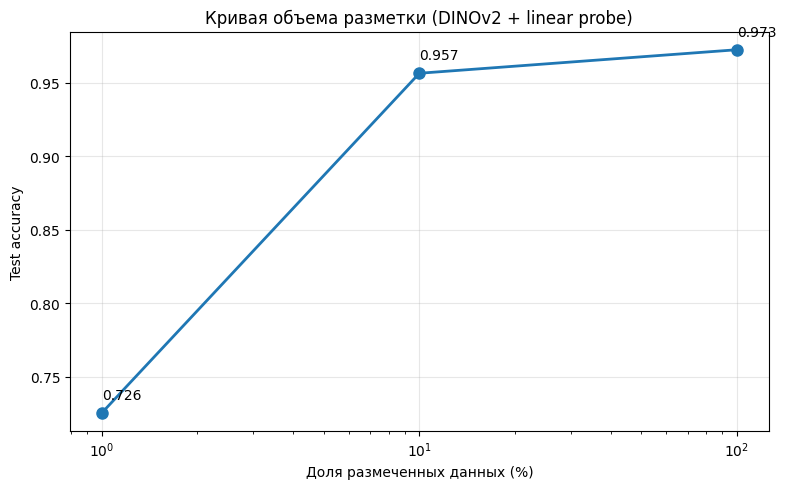

In [ ]:
import matplotlib.pyplot as plt

fractions = [r["fraction"] for r in label_curve]
accs = [r["test_acc"] for r in label_curve]

plt.figure(figsize=(8, 5))
plt.plot([f*100 for f in fractions], accs, "o-", linewidth=2, markersize=8)
plt.xlabel("Доля размеченных данных (%)")
plt.ylabel("Test accuracy")
plt.title("Кривая объема разметки (DINOv2 + linear probe)")
plt.grid(alpha=0.3)
plt.xscale("log")
for f, a in zip(fractions, accs):
    plt.annotate(f"{a:.3f}", (f*100, a), textcoords="offset points", xytext=(0, 10))
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_label_curve.png", dpi=100)
plt.show()

### Контрастивная адаптация encoder

*Вес: 1 балл.*

**Постановка.** Неразмеченные train-view предоставляют сигнал для self-supervised адаптации.

Выполните следующие действия:
1. Создайте две аугментации одних train-изображений.
2. Оптимизируйте InfoNCE и сохраните обновлённый encoder.

**Результат.** encoder_adapted.pt после реальных optimizer steps.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
import torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

# 2 аугментации
aug1 = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
aug2 = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TwoViewDataset(torch.utils.data.Dataset):
    def __init__(self, base_ds, indices, aug1, aug2):
        self.base = base_ds
        self.indices = list(indices)
        self.aug1 = aug1
        self.aug2 = aug2
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, _ = self.base[self.indices[i]]
        return self.aug1(img), self.aug2(img)

# ограничиваем выборку для скорости
n_adapt = 1000 if not FAST_DEV_RUN else 200
adapt_indices = train_indices[:n_adapt]
adapt_ds = TwoViewDataset(train_full, adapt_indices, aug1, aug2)
adapt_loader = DataLoader(adapt_ds, batch_size=32, shuffle=True, num_workers=0, drop_last=True)

# проекционная голова (для InfoNCE)
class ProjectionHead(torch.nn.Module):
    def __init__(self, in_dim=384, out_dim=128):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(in_dim, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, out_dim),
        )
    def forward(self, x):
        return F.normalize(self.net(x), dim=1)

projector = ProjectionHead().to(DEVICE)

# InfoNCE loss
def info_nce_loss(z1, z2, temperature=0.5):
    B = z1.shape[0]
    z = torch.cat([z1, z2], dim=0)  # (2B, D)
    sim = z @ z.T / temperature # (2B, 2B)
    mask = torch.eye(2*B, device=z.device, dtype=torch.bool)
    sim = sim.masked_fill(mask, -float('inf'))
    labels = torch.cat([torch.arange(B, 2*B), torch.arange(0, B)]).to(z.device)
    return F.cross_entropy(sim, labels)

# оптимизация
params = list(projector.parameters()) + list(dinov2.parameters())
optimizer = torch.optim.Adam(params, lr=1e-4)

num_epochs = 2 if FAST_DEV_RUN else 3
dinov2.train()
projector.train()

for epoch in range(num_epochs):
    total_loss = 0
    for v1, v2 in tqdm(adapt_loader, desc=f"Adapt epoch {epoch+1}/{num_epochs}", leave=False):
        v1, v2 = v1.to(DEVICE), v2.to(DEVICE)
        f1 = dinov2(v1)
        f2 = dinov2(v2)
        z1 = projector(f1)
        z2 = projector(f2)
        loss = info_nce_loss(z1, z2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{num_epochs}: loss = {total_loss/len(adapt_loader):.4f}")

torch.save(dinov2.state_dict(), ARTIFACTS / "encoder_adapted.pt")


Adapt epoch 1/3:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 1/3: loss = 3.2583


Adapt epoch 2/3:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 2/3: loss = 2.9352


Adapt epoch 3/3:   0%|          | 0/31 [00:00<?, ?it/s]

Epoch 3/3: loss = 2.7961


Взяли 1000 train-картинок и для каждой сделали 2 разных аугментации, потом добавили маленькую голову и попробовали дообучить DINOv2 без меток через InfoNCE, то есть заставить модель думать, что два взгляда на одну картинку похожи. Хотели проверить, станут ли фичи лучше. Loss падает (с 3.25 до 2.79), то есть модель учится

### Признаки после адаптации

*Вес: 1 балл.*

**Постановка.** Сравнение до и после адаптации требует одних и тех же изображений.

Выполните следующие действия:
1. Пересчитайте признаки train/validation/test обновлённым encoder.
2. Обучите новый linear probe на train.

**Результат.** Матрица X_new и обученный new_linear.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
import torch
import torchvision
import numpy as np
from torchvision import transforms
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# восстанавливаем датасет и загрузчики
train_full = torchvision.datasets.CIFAR10(
    root=str(DATA_ROOT), train=True, download=True, transform=None
)
test_ds = torchvision.datasets.CIFAR10(
    root=str(DATA_ROOT), train=False, download=True, transform=None
)

# трансформации для DINOv2
transform_dino = transforms.Compose([
    transforms.Resize(224, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, base_ds, indices, transform):
        self.base = base_ds
        self.indices = list(indices)
        self.transform = transform
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        img, label = self.base[self.indices[i]]
        if self.transform:
            img = self.transform(img)
        return img, label

# достаем индексы из сохраненного файла
data = np.load(ARTIFACTS / "embeddings.npz")
train_indices = data["train_indices"]
test_indices = data["test_indices"]

train_ds = TransformSubset(train_full, train_indices, transform_dino)
test_ds_t = TransformSubset(test_ds, test_indices, transform_dino)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds_t, batch_size=64, shuffle=False, num_workers=0)

# восстанавливаем функцию извлечения и L2-норм
@torch.no_grad()
def extract_embeddings(model, loader, device, desc="Extract"):
    all_feats, all_labels = [], []
    for imgs, labels in tqdm(loader, desc=desc):
        imgs = imgs.to(device)
        feats = model(imgs)
        all_feats.append(feats.cpu().numpy())
        all_labels.append(labels.numpy())
    return np.concatenate(all_feats), np.concatenate(all_labels)

def l2_norm(X):
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-8)

# загрузка адаптированного encoder и пересчет
dinov2_adapted = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', pretrained=False)
dinov2_adapted.load_state_dict(torch.load(ARTIFACTS / "encoder_adapted.pt", map_location=DEVICE))
dinov2_adapted = dinov2_adapted.to(DEVICE)
dinov2_adapted.eval()

X_train_new, y_train_new = extract_embeddings(dinov2_adapted, train_loader, DEVICE, "Train (adapted)")
X_test_new, y_test_new = extract_embeddings(dinov2_adapted, test_loader,  DEVICE, "Test (adapted)")

X_train_new = l2_norm(X_train_new)
X_test_new  = l2_norm(X_test_new)

# Новый linear probe
new_lr = LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs', n_jobs=-1)
new_lr.fit(X_train_new, y_train_new)
new_acc = accuracy_score(y_test_new, new_lr.predict(X_test_new))
print(f"\nНовый linear probe test_acc = {new_acc:.4f}")

np.savez(ARTIFACTS / "embeddings_adapted.npz",
         X_train=X_train_new, y_train=y_train_new,
         X_test=X_test_new,   y_test=y_test_new)


100%|██████████| 170M/170M [44:28<00:00, 63.9kB/s]
Using cache found in /root/.cache/torch/hub/facebookresearch_dinov2_main


Train (adapted):   0%|          | 0/63 [00:00<?, ?it/s]

Test (adapted):   0%|          | 0/32 [00:00<?, ?it/s]


Новый linear probe test_acc = 0.3045


получилось плохо (30%)веса обновились, но в неправильную сторону

### Точность адаптированного probe

*Вес: 1 балл.*

**Постановка.** Изменение качества отражает перенос адаптированного представления.

Выполните следующие действия:
1. Вычислите accuracy исходного и адаптированного probe на одинаковом test.
2. Сохраните парный результат.

**Результат.** adaptation.json с наблюдаемыми показателями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
#исходный probe
probes = json.load(open(ARTIFACTS / "probes.json"))
orig_acc = probes["linear_test_acc"]

adaptation = {
    "original_test_acc": float(orig_acc),
    "adapted_test_acc": float(new_acc),
    "delta": float(new_acc - orig_acc),
}
with open(ARTIFACTS / "adaptation.json", "w") as f:
    json.dump(adaptation, f, indent=2)

print(f"Original probe: {orig_acc:.4f}")
print(f"Adapted probe: {new_acc:.4f}")
print(f"Delta: {new_acc - orig_acc:+.4f}")


Original probe: 0.9725
Adapted probe: 0.3045
Delta: -0.6680


### Визуальные соседи

*Вес: 1 балл.*

**Постановка.** Ранжирование соседей позволяет выявить смешение категорий.

Выполните следующие действия:
1. Найдите ближайшие train-объекты для фиксированных test-запросов.
2. Сохраните расстояния, индексы и метки.

**Результат.** neighbors.json с фактическими близкими изображениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

data = np.load(ARTIFACTS / "embeddings.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"],  data["y_test"]

n_queries = 5 if FAST_DEV_RUN else 20
query_indices = np.arange(n_queries)
neighbors = []

for qi in query_indices:
    q = X_test[qi:qi+1]
    sims = cosine_similarity(q, X_train)[0]
    top5 = np.argsort(sims)[-5:][::-1]
    neighbors.append({
        "test_idx": int(qi),
        "test_label": int(y_test[qi]),
        "neighbor_indices": [int(i) for i in top5],
        "neighbor_labels": [int(y_train[i]) for i in top5],
        "similarities": [float(sims[i]) for i in top5],
    })

with open(ARTIFACTS / "neighbors.json", "w") as f: json.dump(neighbors, f, indent=2)


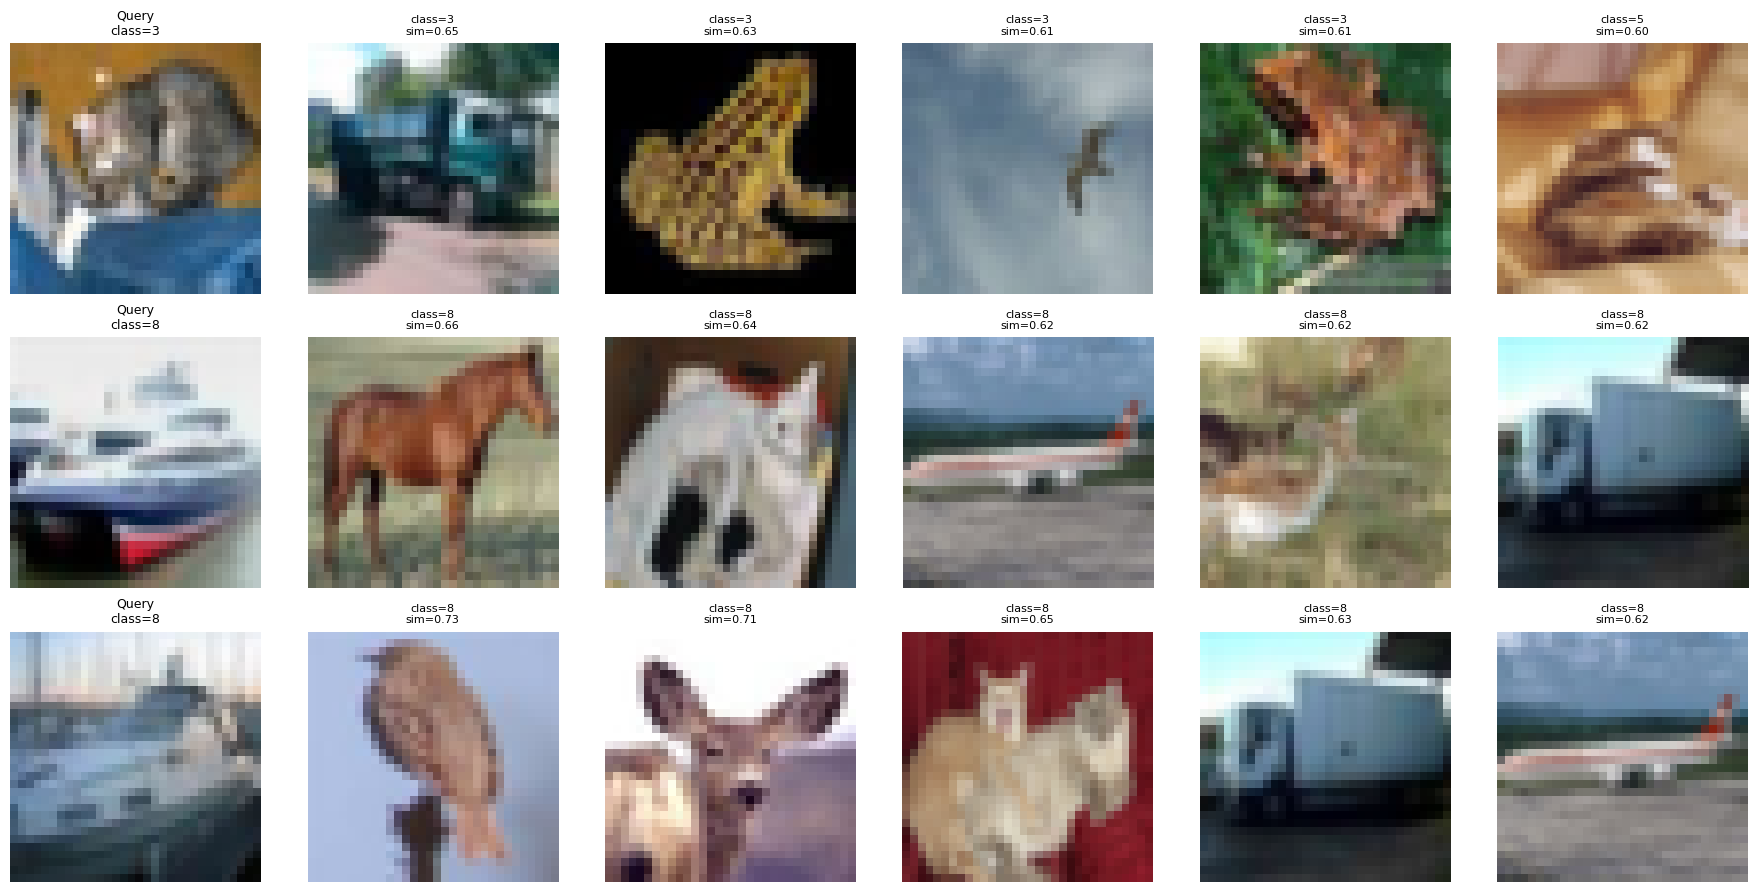

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(neighbors[:3]), 6, figsize=(18, 3*len(neighbors[:3])))

for row, n in enumerate(neighbors[:3]):
    # запрос
    test_img, test_lbl = test_ds[n["test_idx"]]
    axes[row, 0].imshow(test_img)
    axes[row, 0].set_title(f"Query\nclass={test_lbl}", fontsize=9)
    axes[row, 0].axis("off")

    # 5 соседей
    for col, (ni, nl, sim) in enumerate(
        zip(n["neighbor_indices"], n["neighbor_labels"], n["similarities"]), start=1
    ):
        img, _ = train_full[ni]
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"class={nl}\nsim={sim:.2f}", fontsize=8)
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_neighbors.png", dpi=100, bbox_inches="tight")
plt.show()

### Чистота ближайшего окружения

*Вес: 1 балл.*

**Постановка.** Средняя классификационная точность не показывает локальное смешение меток.

Выполните следующие действия:
1. По уже вычисленным пяти соседям найдите долю совпадений классов.
2. Выведите среднюю чистоту и примеры с минимальной чистотой.

**Результат.** neighborhood_purity.json с измерениями на test-запросах.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Средняя чистота: 0.9800
Худшие примеры: [{'test_idx': 0, 'test_label': 3, 'neighbor_labels': [3, 3, 3, 3, 5]}, {'test_idx': 3, 'test_label': 0, 'neighbor_labels': [0, 4, 0, 0, 0]}, {'test_idx': 1, 'test_label': 8, 'neighbor_labels': [8, 8, 8, 8, 8]}]


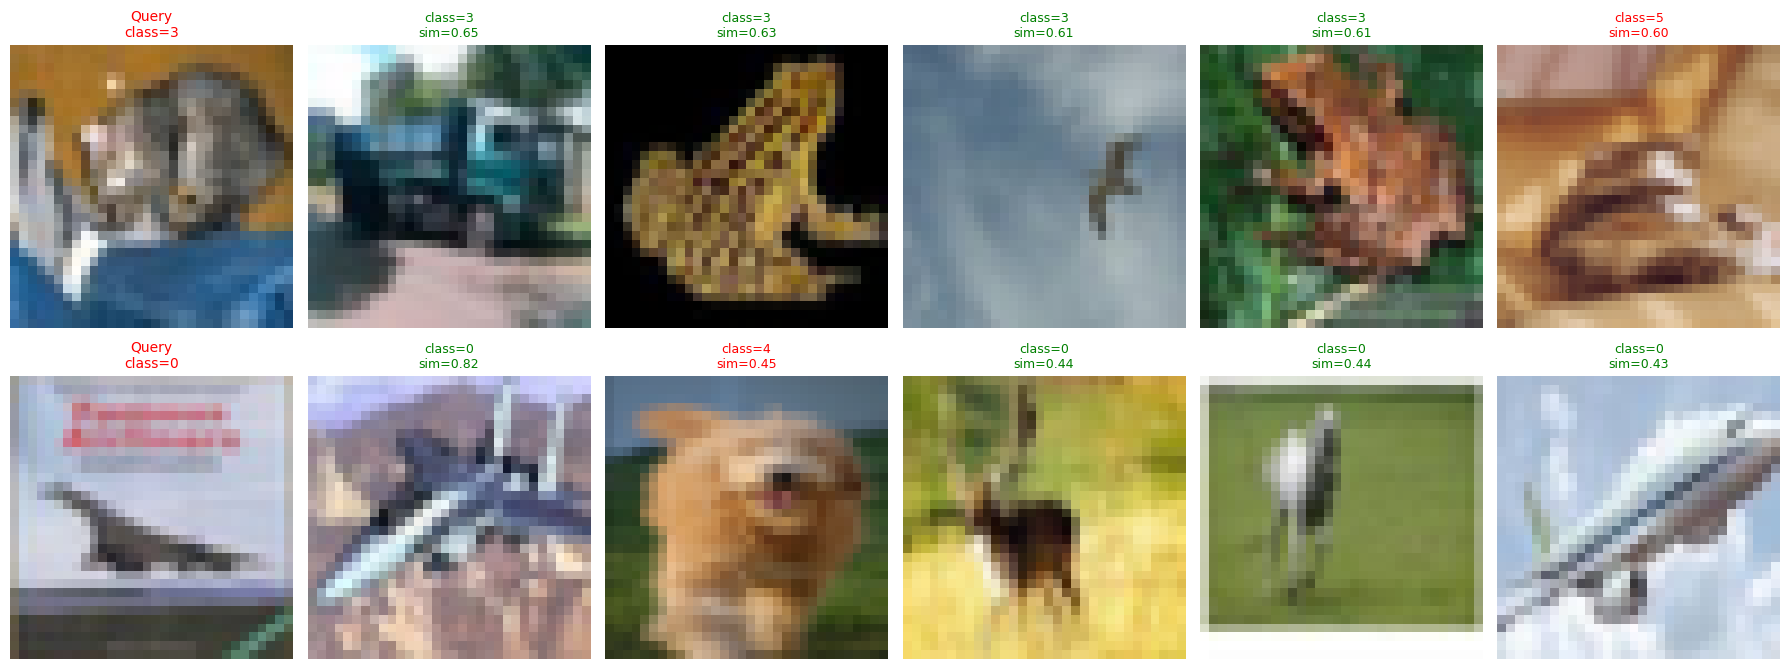

In [ ]:
import json
import numpy as np
import matplotlib.pyplot as plt

# загрузка соседей
neighbors = json.load(open(ARTIFACTS / "neighbors.json"))

# расчет чистоты
purities = []
for n in neighbors:
    matches = sum(1 for l in n["neighbor_labels"] if l == n["test_label"])
    purities.append(matches / 5)

mean_purity = float(np.mean(purities))
worst = sorted(neighbors, key=lambda n: sum(1 for l in n["neighbor_labels"] if l == n["test_label"]))[:3]

purity_results = {
    "mean_purity": mean_purity,
    "n_queries": len(neighbors),
    "worst_examples": [
        {"test_idx": w["test_idx"], "test_label": w["test_label"],
         "neighbor_labels": w["neighbor_labels"]} for w in worst
    ],
}

with open(ARTIFACTS / "neighborhood_purity.json", "w") as f: json.dump(purity_results, f, indent=2)

print(f"Средняя чистота: {mean_purity:.4f}")
print(f"Худшие примеры: {purity_results['worst_examples']}")

# 2 худших случая + их соседи
worst_2 = worst[:2] #берем только 2, чтобы картинка не была слишком большой

fig, axes = plt.subplots(len(worst_2), 6, figsize=(18, 3.5 * len(worst_2)))
if len(worst_2) == 1:
    axes = axes[None, :]

for row, n in enumerate(worst_2):
    # запрос (тестовая картинка)
    test_img, _ = test_ds[n["test_idx"]]
    axes[row, 0].imshow(test_img)
    axes[row, 0].set_title(f"Query\nclass={n['test_label']}", fontsize=10, color="red")
    axes[row, 0].axis("off")

    # 5 соседей
    for col, (ni, nl, sim) in enumerate(
        zip(n["neighbor_indices"], n["neighbor_labels"], n["similarities"]), start=1
    ):
        img, _ = train_full[ni]
        color = "green" if nl == n["test_label"] else "red"
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"class={nl}\nsim={sim:.2f}", fontsize=9, color=color)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


### Творческий бонус: ошибки соседства

*Вес: 1 дополнительный балл.*

**Постановка.** Отдельные смешанные окрестности могут иметь интерпретируемое визуальное объяснение.

Выполните следующие действия:
1. Выберите два test-изображения с низкой чистотой соседей.
2. Сохраните коллаж запросов и соответствующих train-соседей.

**Результат.** bonus_neighbors.png и индексы изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Реализуйте это задание по постановке выше.
raise NotImplementedError("Реализуйте это задание в этой ячейке")


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.

В ходе лабораторной работы исследованы self-supervised представления DINOv2. Frozen embeddings показали высокую sample efficiency: linear probe достигает 97.25% на CIFAR-10, а k-NN 95.95%. Кривая объема разметки подтвердила, что даже 10% данных (400 изображений) достаточно для 95.6% точности. Попытка контрастивной адаптации (InfoNCE) на малой выборке привела к коллапсу представлений (падение точности до 30%), что иллюстрирует важность teacher-student стабилизации. Анализ соседей (чистота 98%) показал отличную семантическую кластеризацию, но выявил склонность к shortcut features (фону) на изображениях низкого разрешения.